# Credify synthetic credit data — exploration

> **Synthetic, educational data.** Every borrower here was generated by `credify_ml.generate` from a documented process (see `docs/ML_STRATEGY.md` and the dataset manifest). Patterns describe that simulation, not any real population.

This notebook looks at the **training split only**, so the validation and test splits stay unseen. The pipeline (`python -m credify_ml.generate`, `python -m credify_ml.train`) is the source of truth; nothing here feeds back into it.

Run `uv run python -m credify_ml.generate` from `ml/` first.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from app.modules.credit_risk.features import FEATURES, FEATURE_NAMES
from credify_ml.config import AUDIT_FILE, DATA_DIR, ID, LABEL
from credify_ml.train import load_dataset, split

frame, manifest = load_dataset(DATA_DIR)  # verifies the content hash
train = split(frame, manifest['seed'])['train']
print(f"{manifest['generator_version']}, seed {manifest['seed']}: "
      f"{len(frame):,} rows, training split {len(train):,} rows")
print('content SHA-256', manifest['content_sha256']['borrowers'])
print(f"default rate (training split): {train[LABEL].mean():.2%}")

synthgen-1.0.0, seed 20261118: 50,000 rows, training split 35,000 rows
content SHA-256 d75655dceeb35cb6dbdc5f2d9b7ceb684a87ca86c1beb283d41c8c661e5c289e
default rate (training split): 11.73%


## The features

One definition, shared with the API: `app/modules/credit_risk/features.py`.

In [2]:
pd.DataFrame([{'feature': s.name, 'kind': s.kind.value, 'nullable': s.nullable,
               'description': s.description} for s in FEATURES])

,feature,kind,nullable,description
0,gross_monthly_income,money,False,Gross monthly income (G)
1,net_monthly_income,money,False,Net monthly income (N)
2,employment_type,category,False,Current employment type
3,employment_tenure_months,count,False,Months in current employment
4,living_expenses_applied,money,False,Living expenses used by affordability: max(dec...
5,existing_debt_instalments,money,False,Monthly instalments on existing credit (C)
6,num_credit_accounts,count,False,Open credit accounts
7,revolving_utilisation,ratio,True,Revolving balance ÷ limit (missing when there ...
8,missed_payments_12m,count,False,Missed payments in the last 12 months
9,months_since_delinquency,count,True,Months since the last delinquency (missing whe...


In [3]:
train[list(FEATURE_NAMES)].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
gross_monthly_income,35000.0,23246.441,16668.306,1500.000,12208.328,20088.525,30248.300,307524.290
net_monthly_income,35000.0,18395.756,12269.986,967.240,10227.500,16370.505,23909.455,235526.300
employment_tenure_months,35000.0,38.893,38.537,0.000,10.000,28.000,57.000,336.000
living_expenses_applied,35000.0,8342.215,5925.998,2000.000,4245.938,7095.510,10863.600,169305.080
existing_debt_instalments,35000.0,1763.611,2821.089,0.000,0.000,739.755,2379.548,51220.120
num_credit_accounts,35000.0,1.239,1.177,0.000,0.000,1.000,2.000,9.000
revolving_utilisation,16760.0,0.421,0.233,0.003,0.244,0.394,0.564,1.199
missed_payments_12m,35000.0,0.322,0.786,0.000,0.000,0.000,0.000,7.000
months_since_delinquency,11404.0,27.236,29.252,0.000,5.000,10.000,49.000,96.000
requested_amount,35000.0,41616.629,34948.382,5000.000,16500.000,31000.000,55500.000,150000.000


## Missing values carry meaning

`revolving_utilisation` is missing when there is no revolving credit, and `months_since_delinquency` when there has never been a delinquency. The model pipeline imputes them and adds missing-value indicators rather than dropping rows.

In [4]:
missing = train[list(FEATURE_NAMES)].isna().mean()
missing[missing > 0].round(3).to_frame('share missing')

,share missing
revolving_utilisation,0.521
months_since_delinquency,0.674


In [5]:
for column in ['revolving_utilisation', 'months_since_delinquency']:
    rates = train.groupby(train[column].isna())[LABEL].mean()
    print(f"{column}: default rate when present {rates[False]:.2%}, "
          f"when missing {rates[True]:.2%}")

revolving_utilisation: default rate when present 13.35%, when missing 10.25%
months_since_delinquency: default rate when present 17.36%, when missing 9.01%


## Default rate by category

In [6]:
def rate_by(column):
    return (train.groupby(column, observed=True)[LABEL]
            .agg(default_rate='mean', borrowers='size')
            .sort_values('default_rate', ascending=False).round(4))

rate_by('employment_type')

,default_rate,borrowers
employment_type,,
UNEMPLOYED,0.2241,1553
RETIRED,0.1427,2362
PART_TIME,0.1402,4108
CONTRACT,0.1303,4942
SELF_EMPLOYED,0.1278,3436
PERMANENT,0.0948,18599


In [7]:
rate_by('loan_purpose')

,default_rate,borrowers
loan_purpose,,
BUSINESS,0.1375,1789
MEDICAL,0.1291,2464
DEBT_CONSOLIDATION,0.1245,10323
OTHER,0.1229,1700
PERSONAL,0.1123,7133
HOME_IMPROVEMENT,0.1090,5295
EDUCATION,0.1072,2781
VEHICLE,0.1061,3515


In [8]:
rate_by(train['missed_payments_12m'].clip(upper=4).rename('missed_payments_12m (4 = 4+)'))

,default_rate,borrowers
missed_payments_12m (4 = 4+),,
4.0,0.3930,285
3.0,0.2845,928
2.0,0.2334,2232
1.0,0.1814,2823
0.0,0.0939,28732


## Default rate across affordability deciles

The documented process makes risk rise with debt-to-income and fall with residual income. The curves below are what a model has to recover.

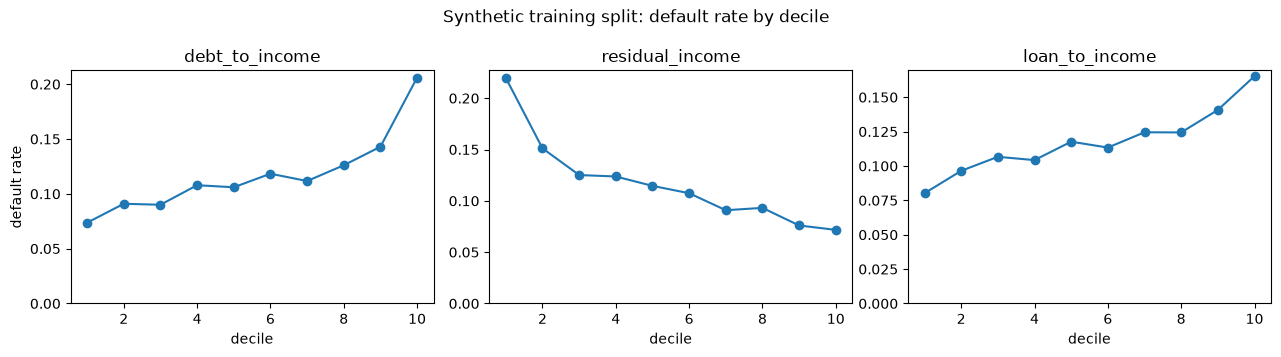

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column in zip(axes, ['debt_to_income', 'residual_income', 'loan_to_income']):
    deciles = pd.qcut(train[column], 10, duplicates='drop')
    rates = train.groupby(deciles, observed=True)[LABEL].mean()
    ax.plot(range(1, len(rates) + 1), rates.values, marker='o')
    ax.set_title(column)
    ax.set_xlabel('decile')
    ax.set_ylim(0, None)
axes[0].set_ylabel('default rate')
fig.suptitle('Synthetic training split: default rate by decile')
fig.tight_layout()

## How the numeric features move together

In [10]:
numeric = [s.name for s in FEATURES if s.kind.value != 'category']
corr = train[numeric + [LABEL]].corr(numeric_only=True)
corr[LABEL].drop(LABEL).sort_values().round(3).to_frame('correlation with default')

,correlation with default
months_since_delinquency,-0.121
residual_income,-0.108
employment_tenure_months,-0.074
net_monthly_income,-0.051
gross_monthly_income,-0.049
living_expenses_applied,-0.035
requested_amount,-0.000
term_months,0.013
existing_debt_instalments,0.042
num_credit_accounts,0.048


## Audit attributes (never features)

`sex` and `age_band` live in a separate file and are joined here only to show the deliberately injected income gap. The model never sees them; the fairness evaluation is part of Phase 7.

In [11]:
audit = pd.read_parquet(DATA_DIR / AUDIT_FILE)
joined = train.merge(audit, on=ID)
summary = joined.groupby('sex').agg(
    median_gross_income=('gross_monthly_income', 'median'),
    median_dti=('debt_to_income', 'median'),
    default_rate=(LABEL, 'mean'),
    borrowers=(LABEL, 'size'),
)
summary.round(4)

,median_gross_income,median_dti,default_rate,borrowers
sex,,,,
F,18799.415,0.1472,0.1181,17528
M,21490.320,0.1501,0.1166,17472


In [12]:
joined.groupby('age_band').agg(
    median_gross_income=('gross_monthly_income', 'median'),
    default_rate=(LABEL, 'mean'),
    borrowers=(LABEL, 'size'),
).round(4)

,median_gross_income,default_rate,borrowers
age_band,,,
18-24,11916.175,0.1414,4264
25-34,20098.750,0.1113,9786
35-44,23168.550,0.1156,8760
45-54,24239.150,0.1169,6294
55-64,21201.490,0.1041,4169
65+,11530.430,0.1343,1727


## Take-aways for modelling

- The default rate sits near the documented 12 % target, so the classes are imbalanced but not extremely so.
- Missingness is informative and must be kept (imputation plus indicators).
- Risk is monotonic in the affordability ratios, which suits an interpretable linear model; gradient boosting is the non-linear challenger.
- Group differences in default arise through income and the features it drives, as designed. Phase 7 measures them formally.